# Notebook to inspect data characteristics

In [45]:
import os
import xarray as xr
import socket
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
import json
#paths
host = socket.gethostname()
if host == 'mpc2959.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = '/mnt/SSD/fische_r/COELY'
    temppath = '/mnt/SSD/fische_r/tmp'
    temppath_2 = '/mpc/homes/fische_r/NAS/tmp'
    training_path = '/mpc/homes/fische_r/NAS/DASCOELY/processing/05_water_GDL_ML/'
elif host == 'mpc2053.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = os.path.join(toppath, 'processing')
    temppath = '/mnt/SSD_2TB_nvme0n1/Robert/tmp/'
    temppath_2 = '/mpc/homes/fische_r/NAS/tmp'
    training_path = '/mpc/homes/fische_r/NAS/DASCOELY/processing/05_water_GDL_ML/'
else:
    print('host '+host+' currently not supported')
    
path_02_4D = os.path.join(toppathSSD, '02_registered_3p1D') #h5 with registered data

In [2]:
samples = ['1', '3III', '3II', '4II', '4', '5', '5II', '6', '7x', '8x']

## Compare grayvalue statistics
use first, last scan and one in the middle

In [4]:
def load_images(sample):
    file = '02_'+sample+'_registered_3p1D.nc'
    imagepath = os.path.join(path_02_4D, file)
    data = xr.open_dataset(imagepath)
    images = [im for im in data.keys() if im[3:7] == 'imag']
    images.sort()
    mnbr = int(len(images)/2)
    first = data[images[0]].data
    last = data[images[-1]].data
    middle = data[images[mnbr]].data
    data.close()
    return first, last, middle

In [6]:
image_dict = {}
for sample in samples:
    first, last, middle = load_images(sample)
    image_dict[sample] = {'first': first, 'middle': middle, 'last': last}

In [12]:
# for sample in samples:
#     first, last, middle = image_dict[sample]
#     image_dict[sample] = {'first': first, 'midlle': middle, 'last': last}

In [11]:
g1 = 5000
g2 = 20000
bins = np.arange(g1,g2,100)

In [49]:
def gray_stats_per_im(im, g1,g2,bins):
    im = im[im>g1]
    im = im[im<g2]
    mean = im.mean()
    std = im.std()
    median = np.median(im)
    hist = np.histogram(im, bins=bins)
    
    return mean, std, median, hist
    


def extract_gray_stats(sample, image_dict, g1, g2, bins):
    sample_stats = {}
    for key in image_dict[sample].keys():
        im = image_dict[sample][key]
        mean, std, median, hist = gray_stats_per_im(im, g1,g2,bins)
        sample_stats[key] = {'mean': mean, 'std': std, 'median': median, 'hist':hist[0]}
    return sample_stats

In [18]:
gray_stats = {}
for sample in samples:
    print(sample)
    gray_stats[sample] = extract_gray_stats(sample, image_dict, g1, g2, bins)

1
3III
3II
4II
4
5
5II
6
7x
8x


(9000.0, 20000.0)

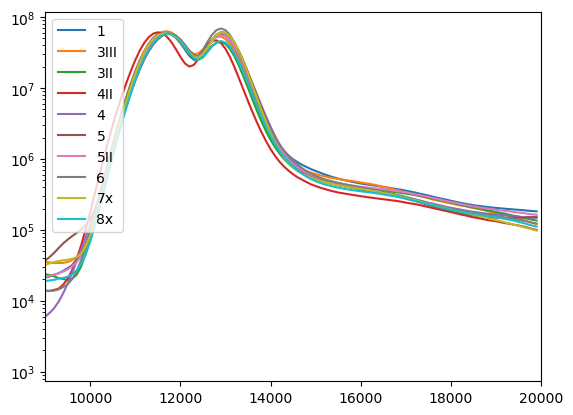

In [43]:
for sample in samples:
    hist = gray_stats[sample]['middle']['hist'][0]
    plt.plot(bins[1:], hist, label=sample)
# plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.xlim(9000,20000)

(9000.0, 15000.0)

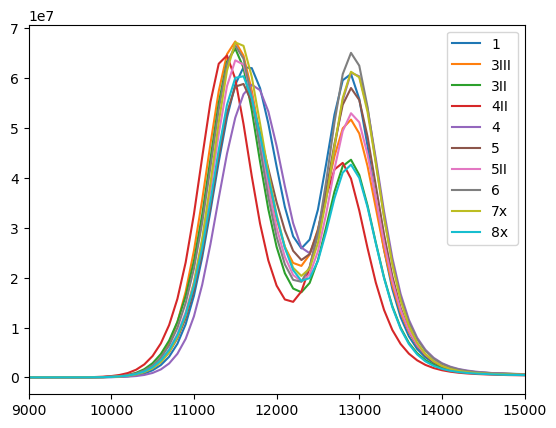

In [26]:
for sample in samples:
    hist = gray_stats[sample]['first']['hist'][0]
    plt.plot(bins[1:], hist, label=sample)
plt.legend()
plt.xlim(9000,15000)

(9000.0, 15000.0)

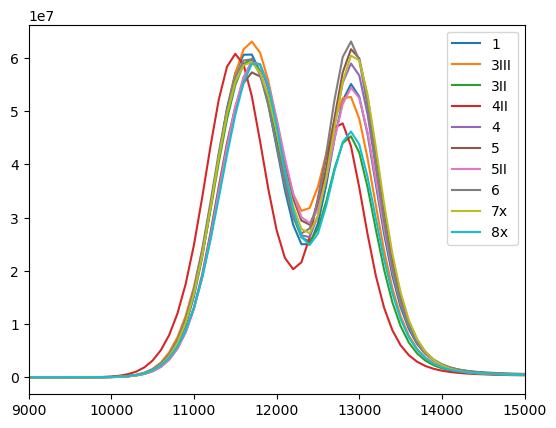

In [27]:
for sample in samples:
    hist = gray_stats[sample]['last']['hist'][0]
    plt.plot(bins[1:], hist, label=sample)
plt.legend()
plt.xlim(9000,15000)

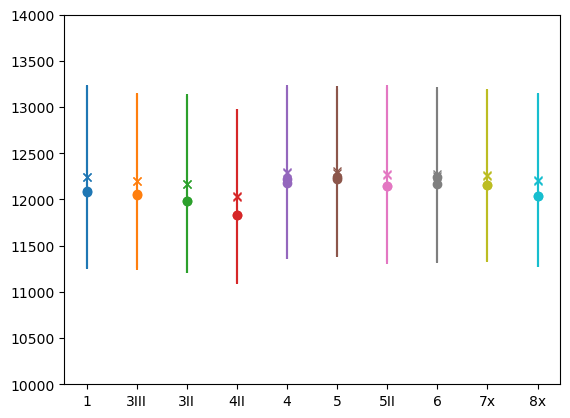

In [39]:
c = 0
for sample in samples:

    med = gray_stats[sample]['last']['median']
    mean = gray_stats[sample]['last']['mean']
    std = gray_stats[sample]['last']['std']
    plt.plot(sample, mean,'x', color = cm.tab10(c))
    plt.errorbar(sample, mean, std, color = cm.tab10(c))
    plt.plot(sample, med, 'o', color = cm.tab10(c))
    c = c +1 
    
plt.ylim(10000, 14000)

c = 0
# for sample in samples:

#     med = gray_stats[sample]['first']['median']
#     mean = gray_stats[sample]['first']['mean']
#     std = gray_stats[sample]['first']['std']
#     plt.plot(sample, mean,'x', color = cm.tab10(c))
#     plt.errorbar(sample, mean, std, color = cm.tab10(c))
#     plt.plot(sample, med,'o', color = cm.tab10(c))
#     c = c +1 
    
# plt.ylim(10000, 14000)

c = 0
for sample in samples:

    med = gray_stats[sample]['midlle']['median']
    mean = gray_stats[sample]['midlle']['mean']
    std = gray_stats[sample]['midlle']['std']
    plt.plot(sample, mean,'x', color = cm.tab10(c))
    plt.errorbar(sample, mean, std, color = cm.tab10(c))
    plt.plot(sample, med,'o', color = cm.tab10(c))
    c = c +1 

## Conclusion
 - histogram virtually identical for all samples except 4II
 - right peak is aluminum flowfields with hidden small peeak >14500 for cathalyst layer
 - left peak is everythinbg else (membrane, air, water, GDL, gaskets)

In [44]:
gray_stats['bins'] = bins

In [47]:
graystatdictpath = os.path.join(toppath, 'processing', 'grayvalue_statistics.json')

In [48]:
with open(graystatdictpath, 'w') as f:
    json.dump(gray_stats, f)

TypeError: Object of type ndarray is not JSON serializable